# Course 16: Algorithms Behind Modern AI
## Session 2: Hashing: dictionaries, the hashing trick and Bloom filters

**Goal:** build an open-addressing hash table and compare its probe counts with Knuth's formulas, see why Python salts string hashes, train a classifier on hashed features of several sizes, and measure the errors of a Bloom filter and a count–min sketch against their formulas.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand first: five keys, eight slots, linear probing
A hash table stores each key in an array of $M$ **slots**. A **hash function** $h$ turns the key into a number, and the key's **home slot** is $h(\text{key}) \bmod M$. Two keys with the same home slot **collide**. With **open addressing** every key lives in the array itself; **linear probing** resolves a collision by trying the next slot, then the next, wrapping around at the end. Each slot looked at is one **probe**.

On paper: $M = 8$ and $h(k) = k$. Insert 10, 18, 3, 7 and 15 in this order and write the table after each step. How many probes does each insertion need? Then search for 18, for 26 and for 11 (a search stops at the key or at the first empty slot). Then run the cell.

In [1]:
import os
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[_v] = "1"              # one thread: repeatable numbers on a shared machine
import sys, time, math, random, hashlib, zlib, subprocess
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

t_start = time.time()

def insert_linear(table, key, h):
    # put key into the first free slot at or after its home slot; return (slot, probes)
    M = len(table)
    i, probes = h(key) % M, 1
    while table[i] is not None and table[i] != key:
        i = (i + 1) % M
        probes += 1
    table[i] = key
    return i, probes

def search_linear(table, key, h):
    # walk from the home slot until the key or an empty slot; return (found, probes)
    M = len(table)
    i, probes = h(key) % M, 1
    while table[i] is not None:
        if table[i] == key:
            return True, probes
        i = (i + 1) % M
        probes += 1
    return False, probes

identity = lambda k: k
table, total = [None] * 8, 0
for key in [10, 18, 3, 7, 15]:
    slot, probes = insert_linear(table, key, identity)
    total += probes
    print(f"insert {key:2d}: home slot {key % 8}, placed in slot {slot}, probes: {probes} -> {table}")
print(f"load factor {5}/{8} = {5 / 8}; probes to find a stored key, on average: {total}/5 = {total / 5}")
for key in [18, 26, 11]:
    found, probes = search_linear(table, key, identity)
    print(f"search {key}: home slot {key % 8}, {'found' if found else 'not in the table'}, probes: {probes}")

insert 10: home slot 2, placed in slot 2, probes: 1 -> [None, None, 10, None, None, None, None, None]
insert 18: home slot 2, placed in slot 3, probes: 2 -> [None, None, 10, 18, None, None, None, None]
insert  3: home slot 3, placed in slot 4, probes: 2 -> [None, None, 10, 18, 3, None, None, None]
insert  7: home slot 7, placed in slot 7, probes: 1 -> [None, None, 10, 18, 3, None, None, 7]
insert 15: home slot 7, placed in slot 0, probes: 2 -> [15, None, 10, 18, 3, None, None, 7]
load factor 5/8 = 0.625; probes to find a stored key, on average: 8/5 = 1.6
search 18: home slot 2, found, probes: 2
search 26: home slot 2, not in the table, probes: 4
search 11: home slot 3, not in the table, probes: 3


### 2. An open-addressing table from scratch: probes against load factor
Now a real table: $M = 2^{15} = 32{,}768$ slots and string keys. The keys are **made-up words** built from random syllables (synthetic data; we reuse them in every section).

The hash function is **FNV-1a**, written out in four lines: start from a fixed number, and for every byte of the key do one XOR and one multiplication. It is the function that fastText uses to hash character n-grams.

The **load factor** is $\alpha = n / M$, the share of slots in use. For linear probing with a hash function that spreads keys evenly, Knuth's analysis gives the expected number of probes:

$$\text{successful search} \approx \tfrac12\Big(1 + \frac{1}{1-\alpha}\Big), \qquad \text{unsuccessful search} \approx \tfrac12\Big(1 + \frac{1}{(1-\alpha)^2}\Big).$$

These are **expected** costs: constant as long as $\alpha$ stays away from 1. The **worst case** is $O(n)$, and a poor hash function reaches it. To see that, the last lines use a deliberately bad hash, the sum of the bytes: all anagrams collide, and all the sums fall in a narrow range.

first made-up words: ['nocajosa', 'nekorema', 'rufike', 'divuji', 'kudicu', 'ratedi', 'palavo', 'tarepe']

FNV-1a, M = 32,768 slots
 load | keys   | successful: measured, Knuth | unsuccessful: measured, Knuth
 0.10 |  3,276 |                1.057  1.056 |                   1.12    1.12
 0.25 |  8,192 |                1.172  1.167 |                   1.42    1.39
 0.50 | 16,384 |                1.500  1.500 |                   2.54    2.50
 0.75 | 24,576 |                2.440  2.500 |                   8.48    8.50
 0.90 | 29,491 |                5.007  5.500 |                  46.72   50.50


 0.95 | 31,129 |               10.066 10.500 |                 233.75  200.50



byte-sum hash at load 0.10 (3,276 keys): successful search 1,382.5 probes, unsuccessful 2,982.1
different home slots among these keys: byte sum 266, FNV-1a 3,116
an anagram pair: bolate tebola -> sum of the bytes: 631 and 631


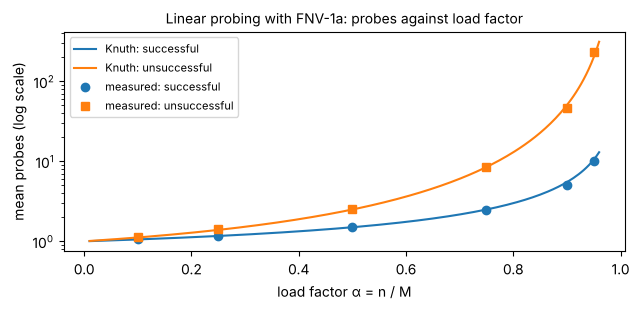

In [2]:
CONS, VOWELS = "bcdfghjklmnprstvz", "aeiou"
SYLLABLES = [c + v for c in CONS for v in VOWELS]             # 85 syllables such as "ba", "ke", "zu"

def make_words(n, seed=0):
    # n different made-up words of two to four syllables, in a fixed order
    r, words, seen = random.Random(seed), [], set()
    while len(words) < n:
        w = "".join(r.choice(SYLLABLES) for _ in range(r.choice([2, 3, 3, 4])))
        if w not in seen:
            seen.add(w); words.append(w)
    return words

WORDS = make_words(40_000)
print("first made-up words:", WORDS[:8])

def fnv1a(data):
    # FNV-1a, 32 bits: one XOR and one multiplication per byte
    h = 2166136261
    for byte in data:
        h ^= byte
        h = (h * 16777619) & 0xFFFFFFFF
    return h

def byte_sum(data):
    return sum(data)                                           # a bad hash function, for comparison

def fill_and_measure(M, keys, absent, h):
    # insert keys one by one; return (mean probes of a successful search, mean probes of an unsuccessful one)
    table, total = [None] * M, 0
    for key in keys:
        total += insert_linear(table, key, h)[1]               # finding a key later takes the probes its insertion took
    miss = sum(search_linear(table, key, h)[1] for key in absent)
    return total / len(keys), miss / len(absent)

M = 2 ** 15
h_fnv = lambda w: fnv1a(w.encode())
h_sum = lambda w: byte_sum(w.encode())
absent = WORDS[38_000:]                                        # 2,000 words that are never inserted
alphas, measured = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95], []
print(f"\nFNV-1a, M = {M:,d} slots")
print(" load | keys   | successful: measured, Knuth | unsuccessful: measured, Knuth")
for a in alphas:
    n = int(a * M)
    s, u = fill_and_measure(M, WORDS[:n], absent, h_fnv)
    measured.append((s, u))
    print(f" {a:4.2f} | {n:6,d} | {s:20.3f} {0.5 * (1 + 1 / (1 - a)):6.3f} | {u:22.2f} {0.5 * (1 + 1 / (1 - a) ** 2):7.2f}")

n = int(0.10 * M)
s_bad, u_bad = fill_and_measure(M, WORDS[:n], absent[:200], h_sum)
print(f"\nbyte-sum hash at load 0.10 ({n:,d} keys): successful search {s_bad:,.1f} probes, unsuccessful {u_bad:,.1f}")
print(f"different home slots among these keys: byte sum {len({h_sum(w) % M for w in WORDS[:n]}):,d}, FNV-1a {len({h_fnv(w) % M for w in WORDS[:n]}):,d}")
print("an anagram pair:", "".join(SYLLABLES[k] for k in (3, 40, 71)), "".join(SYLLABLES[k] for k in (71, 3, 40)),
      "-> sum of the bytes:", h_sum(SYLLABLES[3] + SYLLABLES[40] + SYLLABLES[71]), "and", h_sum(SYLLABLES[71] + SYLLABLES[3] + SYLLABLES[40]))

aa = np.linspace(0.01, 0.96, 200)
plt.figure(figsize=(6.5, 3.2))
plt.semilogy(aa, 0.5 * (1 + 1 / (1 - aa)), "C0-", label="Knuth: successful")
plt.semilogy(aa, 0.5 * (1 + 1 / (1 - aa) ** 2), "C1-", label="Knuth: unsuccessful")
plt.semilogy(alphas, [s for s, _ in measured], "C0o", label="measured: successful")
plt.semilogy(alphas, [u for _, u in measured], "C1s", label="measured: unsuccessful")
plt.xlabel("load factor α = n / M"); plt.ylabel("mean probes (log scale)")
plt.title("Linear probing with FNV-1a: probes against load factor", fontsize=10); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3. Python salts its string hashes
Python's built-in `hash()` of a string is **salted**: each new Python process picks a random secret and mixes it into every string hash. The reason is security. If a web server's hash function were public and fixed, an attacker could send thousands of keys that all land in the same slot and turn every dictionary operation into the $O(n)$ worst case of section 2.

So `hash("a")` changes from one run to the next. That is fine inside a dictionary, which lives and dies with its process. It is a bug as soon as the value leaves the process: stored in a file, used to choose a bucket for features, or used to split data into train and test. For anything that must be the same tomorrow, use a hash you define (`fnv1a` above), `zlib.crc32` or `hashlib`.

The cell starts new Python processes and compares what they print. It prints only whether the values agree, because the values themselves differ on every run.

In [3]:
def run_python(code, seed=None):
    # run one line of Python in a new process; seed=None means "leave hash randomization as it is by default"
    env = {k: v for k, v in os.environ.items() if k != "PYTHONHASHSEED"}
    if seed is not None:
        env["PYTHONHASHSEED"] = str(seed)
    return subprocess.run([sys.executable, "-c", code], capture_output=True, text=True, env=env, check=True).stdout.strip()

a, b = run_python("print(hash('a'))"), run_python("print(hash('a'))")
print("hash('a') in two new processes: different values?", a != b)
c, d = run_python("print(hash('a'))", seed=0), run_python("print(hash('a'))", seed=0)
print("with the environment variable PYTHONHASHSEED=0 in both: equal values?", c == d)
e, f = run_python("print(hash(42))"), run_python("print(hash(42))")
print("hash(42) in two new processes: equal values?", e == f, "| value:", e, "(small integers hash to themselves)")
g, h = run_python("import zlib; print(zlib.crc32(b'a'))"), run_python("import zlib; print(zlib.crc32(b'a'))")
print("zlib.crc32(b'a') in two new processes:", g, h, "| here:", zlib.crc32(b"a"))
print("our fnv1a(b'a'):", fnv1a(b"a"), "=", hex(fnv1a(b"a")), "| hashlib.md5(b'a'):", hashlib.md5(b"a").hexdigest()[:16], "...")

hash('a') in two new processes: different values? True
with the environment variable PYTHONHASHSEED=0 in both: equal values? True
hash(42) in two new processes: equal values? True | value: 42 (small integers hash to themselves)
zlib.crc32(b'a') in two new processes: 3904355907 3904355907 | here: 3904355907
our fnv1a(b'a'): 3826002220 = 0xe40c292c | hashlib.md5(b'a'): 0cc175b9c0f1b6a8 ...


### 4. The hashing trick: a huge vocabulary in a fixed number of columns
A bag-of-words model needs one column per word, and a dictionary from word to column. The **hashing trick** drops the dictionary: the column of a word is $h(\text{word}) \bmod m$ for a fixed $m$. Memory no longer grows with the vocabulary, and new words need no bookkeeping. The price is collisions: different words share a column.

**Synthetic task.** The first 20,000 made-up words are the vocabulary; word number $r$ has background probability proportional to $1/r$ (a Zipf-like law, as in real text). Each of two topics makes its own 2,000 words four times more likely. A document is 60 words drawn from one topic, and the task is to say which. We train logistic regression on 3,000 documents and test on 2,000:

* on the full count matrix (20,000 columns), and
* on hashed counts with $m = 2^6, \dots, 2^{14}$ columns, **unsigned** (add 1 to the word's column) and **signed** (add $+1$ or $-1$, chosen by one more bit of the hash).

Hashing is a sparse matrix product: `X_hashed = X @ H`, where `H` has one non-zero per word (session 1's CSR). We also count the pairs of words that share a column. For $n$ words in $m$ columns the expected number is $n(n-1)/(2m)$.

one document: neza kokago dokotaki peceniro zido ratacu nocajosa curide vifumo ...
count matrix: 3,000 x 20,000, density 0.0025; different words in the training documents: n = 16,325


full vocabulary, 20,000 columns: test accuracy 0.939

     m | accuracy: signed, unsigned | pairs of words in one column | n(n-1)/(2m) | words alone in their column
    64 |           0.634     0.602 |                    2,081,174 |   2,081,948 |   0.0%
   128 |           0.693     0.657 |                    1,040,280 |   1,040,974 |   0.0%


   256 |           0.729     0.727 |                      519,691 |     520,487 |   0.0%


   512 |           0.773     0.770 |                      260,434 |     260,243 |   0.0%
 1,024 |           0.826     0.825 |                      130,157 |     130,122 |   0.0%


 2,048 |           0.874     0.869 |                       64,819 |      65,061 |   0.0%
 4,096 |           0.906     0.909 |                       32,474 |      32,530 |   1.8%


 8,192 |           0.923     0.928 |                       16,141 |      16,265 |  13.9%


16,384 |           0.932     0.931 |                        8,085 |       8,133 |  36.8%


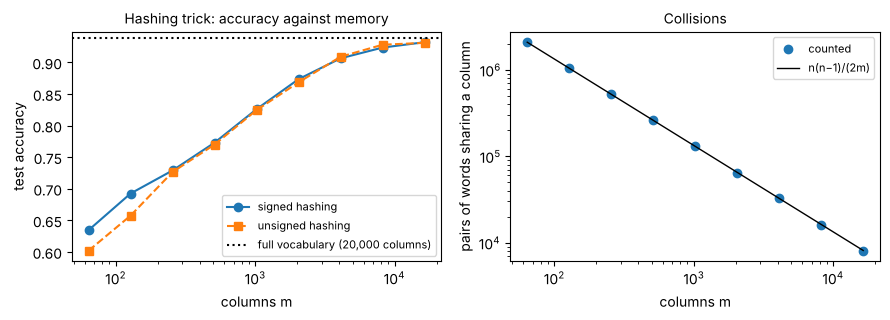

In [4]:
V, DOC_LEN, N_TOPIC, BOOST = 20_000, 60, 2_000, 4.0
rng = np.random.default_rng(0)
p0 = 1.0 / np.arange(1, V + 1); p0 /= p0.sum()                 # Zipf-like background
shuffled = rng.permutation(np.arange(100, V))                   # topic words: not among the 100 most frequent
topic_words = [shuffled[:N_TOPIC], shuffled[N_TOPIC:2 * N_TOPIC]]
p_topic = []
for tw in topic_words:
    p = p0.copy(); p[tw] *= BOOST; p_topic.append(p / p.sum())

def make_docs(n):
    y = rng.integers(0, 2, size=n)
    tokens = np.where(y[:, None] == 0, rng.choice(V, size=(n, DOC_LEN), p=p_topic[0]), rng.choice(V, size=(n, DOC_LEN), p=p_topic[1]))
    return tokens, y

def count_matrix(tokens):
    n = len(tokens)
    X = sp.csr_matrix((np.ones(tokens.size), (np.repeat(np.arange(n), tokens.shape[1]), tokens.ravel())), shape=(n, V))
    X.sum_duplicates()
    return X

tok_train, y_train = make_docs(3000)
tok_test, y_test = make_docs(2000)
X_train, X_test = count_matrix(tok_train), count_matrix(tok_test)
seen = np.unique(tok_train)                                      # the words that occur in the training documents
print("one document:", " ".join(WORDS[t] for t in tok_train[0][:9]), "...")
print(f"count matrix: {X_train.shape[0]:,d} x {X_train.shape[1]:,d}, density {X_train.nnz / (X_train.shape[0] * V):.4f}; "
      f"different words in the training documents: n = {len(seen):,d}")

def word_hashes(seed):
    # one 64-bit hash per vocabulary word; the salt gives an independent hash function for every seed
    salt = seed.to_bytes(8, "little")
    return np.array([int.from_bytes(hashlib.blake2b(w.encode(), digest_size=8, salt=salt).digest(), "little") for w in WORDS[:V]],
                    dtype=np.uint64)

def hashing_matrix(H, m, signed):
    # V x m matrix with one non-zero per word: column = hash mod m, value = +1/-1 from the top bit (signed) or 1
    column = (H % np.uint64(m)).astype(np.int64)
    value = np.where((H >> np.uint64(63)) == 1, 1.0, -1.0) if signed else np.ones(V)
    return sp.csr_matrix((value, (np.arange(V), column)), shape=(V, m)), column

def accuracy(A_train, A_test):
    return LogisticRegression(C=1.0, max_iter=3000).fit(A_train, y_train).score(A_test, y_test)

acc_full = accuracy(X_train, X_test)
print(f"full vocabulary, {V:,d} columns: test accuracy {acc_full:.3f}")
H0 = word_hashes(0)
ms, acc_s, acc_u, pairs = [2 ** k for k in range(6, 15)], [], [], []
print("\n     m | accuracy: signed, unsigned | pairs of words in one column | n(n-1)/(2m) | words alone in their column")
for m in ms:
    Hs, column = hashing_matrix(H0, m, signed=True)
    Hu, _ = hashing_matrix(H0, m, signed=False)
    acc_s.append(accuracy(X_train @ Hs, X_test @ Hs)); acc_u.append(accuracy(X_train @ Hu, X_test @ Hu))
    load = np.bincount(column[seen], minlength=m)                # how many seen words share each column
    pairs.append(int((load * (load - 1) // 2).sum()))
    alone = float((load[column[seen]] == 1).mean())
    print(f"{m:6,d} | {acc_s[-1]:15.3f} {acc_u[-1]:9.3f} | {pairs[-1]:28,d} | {len(seen) * (len(seen) - 1) / (2 * m):11,.0f} | {alone:6.1%}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
ax[0].semilogx(ms, acc_s, "o-", label="signed hashing"); ax[0].semilogx(ms, acc_u, "s--", label="unsigned hashing")
ax[0].axhline(acc_full, color="k", ls=":", label="full vocabulary (20,000 columns)")
ax[0].set_xlabel("columns m"); ax[0].set_ylabel("test accuracy"); ax[0].set_title("Hashing trick: accuracy against memory", fontsize=10)
ax[0].legend(fontsize=8)
ax[1].loglog(ms, pairs, "o", label="counted"); ax[1].loglog(ms, [len(seen) * (len(seen) - 1) / (2 * m) for m in ms], "k-", lw=1, label="n(n−1)/(2m)")
ax[1].set_xlabel("columns m"); ax[1].set_ylabel("pairs of words sharing a column"); ax[1].set_title("Collisions", fontsize=10); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5. Why the sign: collisions as noise, not as bias
A linear model works with inner products $\langle x, y \rangle$. After **unsigned** hashing, every pair of different words that share a column adds a positive amount to the inner product of the hashed vectors, so it is too large on average. Each pair collides with probability $1/m$, which gives a bias of $\big(\sum_i x_i \sum_j y_j - \langle x, y\rangle\big)/m$.

With a random **sign** per word the same pair adds $+x_i y_j$ or $-x_i y_j$ with equal probability. The collisions are still there, but they cancel on average: the hashed inner product is an **unbiased** estimate of the true one (Weinberger et al. 2009).

"On average" means over the choice of hash function. So we use 20 independent hash functions (20 salts) and 998 pairs of test documents, and report the mean of (hashed inner product − true inner product).

In [5]:
pair_i, pair_j = rng.integers(0, 2000, 1000), rng.integers(0, 2000, 1000)
keep = pair_i != pair_j
pair_i, pair_j = pair_i[keep], pair_j[keep]

def row_inner(Z):
    Z = Z.tocsr()
    return np.asarray(Z[pair_i].multiply(Z[pair_j]).sum(axis=1)).ravel()

true_ip = row_inner(X_test)
print(f"{len(true_ip)} pairs of documents; mean true inner product {true_ip.mean():.2f}")
hash_functions = [word_hashes(seed) for seed in range(1, 21)]
print("    m | signed: mean error (standard error) | unsigned: mean error | predicted bias of unsigned")
for m in [64, 256, 1024, 4096]:
    err = {True: [], False: []}
    for H in hash_functions:
        for signed in (True, False):
            Hm, _ = hashing_matrix(H, m, signed)
            err[signed].append(row_inner(X_test @ Hm) - true_ip)
    es, eu = np.array(err[True]), np.array(err[False])
    se = es.mean(axis=1).std(ddof=1) / np.sqrt(len(hash_functions))        # spread over the 20 hash functions
    print(f"{m:5,d} | {es.mean():14.3f} ({se:.3f})             | {eu.mean():20.3f} | {(DOC_LEN * DOC_LEN - true_ip.mean()) / m:10.3f}")

998 pairs of documents; mean true inner product 40.08


    m | signed: mean error (standard error) | unsigned: mean error | predicted bias of unsigned
   64 |         -0.953 (0.738)             |               53.397 |     55.624


  256 |         -0.776 (0.348)             |               13.417 |     13.906
1,024 |         -0.075 (0.130)             |                3.220 |      3.476
4,096 |         -0.004 (0.057)             |                0.823 |      0.869


### 6. A Bloom filter: "have I seen this?" in a few bits per entry
A **Bloom filter** is an array of $m$ bits and $k$ hash functions. To add an entry, set its $k$ bits. To ask about an entry, look at its $k$ bits: if any is 0, the entry was **certainly never added**; if all are 1, it was **probably** added. So there are no false negatives, and the false-positive rate after $n$ additions is about

$$\big(1 - e^{-kn/m}\big)^k, \qquad \text{smallest at } k = \frac{m}{n}\ln 2 .$$

For a 1% rate that is about 9.6 bits per entry, whatever the size of the entries.

We do not need $k$ separate hash functions: two are enough, $g_i(x) = h_1(x) + i \cdot h_2(x) \bmod m$ (Kirsch & Mitzenmacher 2008). Both come from one `hashlib.blake2b` digest.

**Data.** A "training corpus" of 60,000 made-up words in Zipf order; the filter stores 20,000 of its 3-grams (three words in a row). We then ask about 20,000 other 3-grams that are not in the set. This is the shape of MemFree decoding (Ippolito et al. 2023), which checks each n-gram a model is about to write against a Bloom filter of the training set.

stored: 20,000 different 3-gram strings, for example 'soveno luzocu rufike'; queries that were never stored: 20,000

9.6 bits per stored 3-gram; best k = 9.6 ln 2 = 6.65
  k | false negatives | false positives of 20,000 | measured rate | formula
  1 |               0 |                     1,980 |        0.0990 | 0.0989


  2 |               0 |                       679 |        0.0340 | 0.0354
  3 |               0 |                       351 |        0.0175 | 0.0193


  4 |               0 |                       256 |        0.0128 | 0.0135
  5 |               0 |                       196 |        0.0098 | 0.0110


  6 |               0 |                       167 |        0.0083 | 0.0101
  7 |               0 |                       200 |        0.0100 | 0.0100


  8 |               0 |                       215 |        0.0107 | 0.0104
 10 |               0 |                       238 |        0.0119 | 0.0129


 12 |               0 |                       335 |        0.0168 | 0.0174

bits per 3-gram | best k (rounded) | false positives of 20,000 | measured rate | formula | filter bytes
            4.8 |                3 |                     2,024 |        0.1012 | 0.1004  | 12,000


            9.6 |                7 |                       200 |        0.0100 | 0.0100  | 24,000
           14.4 |               10 |                        17 |        0.0008 | 0.0010  | 36,000


           19.2 |               13 |                         4 |        0.0002 | 0.0001  | 48,000

memory for 20,000 stored strings: Bloom filter at 9.6 bits each 24,000 bytes; Python set of the strings 3,332,314 bytes (139 x more)
bits per entry needed for a 1% rate at the best k: ln(100) / (ln 2)^2 = 9.59


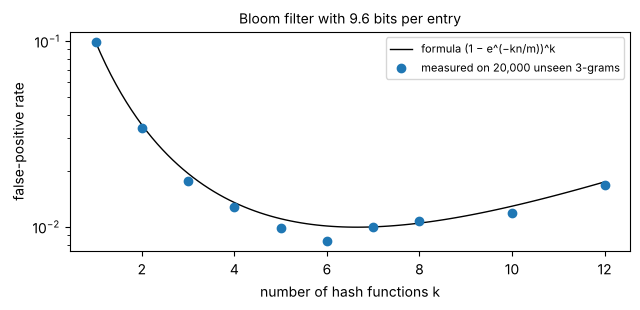

In [6]:
class BloomFilter:
    def __init__(self, m, k):
        self.m, self.k = m, k
        self.bits = bytearray((m + 7) // 8)                    # m bits, all 0

    def _positions(self, entry):
        digest = hashlib.blake2b(entry.encode(), digest_size=16).digest()
        h1, h2 = int.from_bytes(digest[:8], "little"), int.from_bytes(digest[8:], "little")
        return [(h1 + i * h2) % self.m for i in range(self.k)]   # double hashing: k positions from two hashes

    def add(self, entry):
        for j in self._positions(entry):
            self.bits[j >> 3] |= 1 << (j & 7)

    def __contains__(self, entry):
        return all(self.bits[j >> 3] >> (j & 7) & 1 for j in self._positions(entry))

rng_b = np.random.default_rng(1)
corpus = rng_b.choice(V, size=60_000, p=p0)
grams = {}                                                     # a dict keeps the order of first appearance
for i in range(len(corpus) - 2):
    grams[" ".join(WORDS[t] for t in corpus[i:i + 3])] = None
stored = list(grams)[:20_000]
stored_set = set(stored)
other = {}
fresh = rng_b.choice(V, size=80_000, p=p0)
for i in range(len(fresh) - 2):
    g = " ".join(WORDS[t] for t in fresh[i:i + 3])
    if g not in stored_set:
        other[g] = None
unseen = list(other)[:20_000]
n = len(stored)
print(f"stored: {n:,d} different 3-gram strings, for example '{stored[0]}'; queries that were never stored: {len(unseen):,d}")

def test_filter(bits_per_entry, k):
    bf = BloomFilter(int(round(bits_per_entry * n)), k)
    for g in stored:
        bf.add(g)
    false_neg = sum(g not in bf for g in stored)
    false_pos = sum(g in bf for g in unseen)
    return bf, false_neg, false_pos, (1 - math.exp(-k * n / bf.m)) ** k

ks, fp_measured, fp_formula = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12], [], []
print(f"\n9.6 bits per stored 3-gram; best k = 9.6 ln 2 = {9.6 * math.log(2):.2f}")
print("  k | false negatives | false positives of 20,000 | measured rate | formula")
for k in ks:
    bf, fn, fp, formula = test_filter(9.6, k)
    fp_measured.append(fp / len(unseen)); fp_formula.append(formula)
    print(f"{k:3d} | {fn:15d} | {fp:25,d} | {fp / len(unseen):13.4f} | {formula:.4f}")

print("\nbits per 3-gram | best k (rounded) | false positives of 20,000 | measured rate | formula | filter bytes")
for bpe in [4.8, 9.6, 14.4, 19.2]:
    k = max(1, round(bpe * math.log(2)))
    bf, fn, fp, formula = test_filter(bpe, k)
    print(f"{bpe:15.1f} | {k:16d} | {fp:25,d} | {fp / len(unseen):13.4f} | {formula:.4f}  | {len(bf.bits):,d}")

set_bytes = sys.getsizeof(stored_set) + sum(sys.getsizeof(g) for g in stored)
bf = test_filter(9.6, 7)[0]
print(f"\nmemory for {n:,d} stored strings: Bloom filter at 9.6 bits each {len(bf.bits):,d} bytes; Python set of the strings {set_bytes:,d} bytes "
      f"({set_bytes / len(bf.bits):.0f} x more)")
print(f"bits per entry needed for a 1% rate at the best k: ln(100) / (ln 2)^2 = {math.log(100) / math.log(2) ** 2:.2f}")

kk = np.linspace(1, 12, 100)
plt.figure(figsize=(6.5, 3.2))
plt.semilogy(kk, (1 - np.exp(-kk / 9.6)) ** kk, "k-", lw=1, label="formula (1 − e^(−kn/m))^k")
plt.semilogy(ks, fp_measured, "o", label="measured on 20,000 unseen 3-grams")
plt.xlabel("number of hash functions k"); plt.ylabel("false-positive rate")
plt.title("Bloom filter with 9.6 bits per entry", fontsize=10); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7. A count–min sketch: "how often?" in fixed memory
A **count–min sketch** is a table of counters with $d$ rows and $w$ columns, and one hash function per row. To count an entry, add 1 to one counter in every row. To ask for its count, take the **minimum** of its $d$ counters. Other entries can only add to a counter, so the answer is **never too low**. With $w = \lceil e/\varepsilon \rceil$ and $d = \lceil \ln(1/\delta) \rceil$, the answer is too high by at most $\varepsilon N$ with probability at least $1 - \delta$, where $N$ is the length of the stream (Cormode & Muthukrishnan 2005).

The proof needs hash functions that are **pairwise independent**. A classic family is $h(x) = ((a x + b) \bmod p) \bmod w$ with a prime $p$ and random $a, b$; we use it on integer keys.

**Data.** A stream of 200,000 bigrams (pairs of neighbouring words) from a Zipf-like word stream; the key of a bigram is `first_word * V + second_word`. We compare the sketch with exact counts in a dictionary.

In [7]:
PRIME = (1 << 61) - 1

class CountMinSketch:
    def __init__(self, eps, delta, seed=0):
        self.w, self.d = math.ceil(math.e / eps), math.ceil(math.log(1 / delta))
        r = random.Random(seed)
        self.ab = [(r.randrange(1, PRIME), r.randrange(PRIME)) for _ in range(self.d)]    # one hash function per row
        self.rows = [[0] * self.w for _ in range(self.d)]

    def add(self, x):
        for (a, b), row in zip(self.ab, self.rows):
            row[((a * x + b) % PRIME) % self.w] += 1

    def query(self, x):
        return min(row[((a * x + b) % PRIME) % self.w] for (a, b), row in zip(self.ab, self.rows))

rng_c = np.random.default_rng(2)
N = 200_000
word_stream = rng_c.choice(V, size=N + 1, p=p0)
keys = (word_stream[:-1].astype(np.int64) * V + word_stream[1:]).tolist()
exact = {}
for x in keys:
    exact[x] = exact.get(x, 0) + 1
counts = np.array(list(exact.values()))
print(f"stream length N = {N:,d}; different bigram keys: {len(exact):,d}; keys that occur once: {int((counts == 1).sum()):,d}; largest count: {counts.max():,d}")

print("\n   eps | width w | depth d | counters | smallest, mean, largest overestimate | bound eps*N | share above the bound")
for eps in [0.01, 0.001, 0.0001]:
    cms = CountMinSketch(eps, delta=0.01)
    for x in keys:
        cms.add(x)
    over = np.array([cms.query(x) for x in exact]) - counts
    assert over.min() >= 0                                     # never too low
    print(f"{eps:6.4f} | {cms.w:7,d} | {cms.d:7d} | {cms.w * cms.d:8,d} | {over.min():8d} {over.mean():8.1f} {over.max():8d}"
          f"              | {eps * N:11,.0f} | {(over > eps * N).mean():.4f}")
    if eps == 0.001:
        cms_mid, over_mid = cms, over

print("\nwith eps = 0.001: mean overestimate by true count")
for lo, hi in [(1, 1), (2, 9), (10, 99), (100, 10 ** 9)]:
    sel = (counts >= lo) & (counts <= hi)
    label = f"{lo}" if lo == hi else (f"{lo} to {hi}" if hi < 10 ** 9 else f"{lo} or more")
    print(f"  true count {label:11s}: {int(sel.sum()):7,d} keys, mean overestimate {over_mid[sel].mean():5.1f}, relative to the count {np.mean(over_mid[sel] / counts[sel]):6.2f}")

threshold = 100
heavy_true = {x for x, c in exact.items() if c >= threshold}
heavy_sketch = {x for x in exact if cms_mid.query(x) >= threshold}
print(f"keys with count >= {threshold}: {len(heavy_true)} in truth; the sketch reports {len(heavy_sketch)} "
      f"(missed: {len(heavy_true - heavy_sketch)}, reported wrongly: {len(heavy_sketch - heavy_true)})")
print(f"memory: sketch {4 * cms_mid.w * cms_mid.d:,d} bytes with 4-byte counters; the exact dictionary's table alone {sys.getsizeof(exact):,d} bytes")
print(f"runtime so far {time.time() - t_start:.0f} s")

stream length N = 200,000; different bigram keys: 136,412; keys that occur once: 121,761; largest count: 1,836

   eps | width w | depth d | counters | smallest, mean, largest overestimate | bound eps*N | share above the bound


0.0100 |     272 |       5 |    1,360 |      525    628.9      851              |       2,000 | 0.0000


0.0010 |   2,719 |       5 |   13,595 |       24     49.8      102              |         200 | 0.0000


0.0001 |  27,183 |       5 |  135,915 |        0      2.9       11              |          20 | 0.0000

with eps = 0.001: mean overestimate by true count
  true count 1          : 121,761 keys, mean overestimate  49.7, relative to the count  49.70
  true count 2 to 9     :  13,542 keys, mean overestimate  50.3, relative to the count  20.21
  true count 10 to 99   :   1,051 keys, mean overestimate  51.3, relative to the count   3.15
  true count 100 or more:      58 keys, mean overestimate  50.8, relative to the count   0.30


keys with count >= 100: 58 in truth; the sketch reports 145 (missed: 0, reported wrongly: 87)
memory: sketch 54,380 bytes with 4-byte counters; the exact dictionary's table alone 5,242,960 bytes
runtime so far 8 s


### 8. Exercises

In [8]:
# TODO: size a Bloom filter. Write bloom_size(n, p) that returns (m, k): the number of bits m = ceil(-n ln p / (ln 2)^2)
# and the number of hash functions k = round((m / n) ln 2) for n entries and a target false-positive rate p.
# Check bloom_size(20_000, 0.01) against section 6, then size a filter for 1 billion 50-token n-grams at p = 0.001:
# how many gigabytes? Compare with storing the n-grams themselves.
def bloom_size(n, p):
    return None          # replace with your code

r = bloom_size(20_000, 0.01)
print("not done yet" if r is None else r)

not done yet


In [9]:
# TODO: deletion in an open-addressing table. Simply emptying a slot breaks later searches (why? try it on section 1's
# table: delete 18, then search for 3). Write delete_linear(table, key, h) that puts a special marker TOMBSTONE into
# the slot, and change search_linear and insert_linear so that a search walks past tombstones and an insertion may
# reuse them. Test: after deleting 18 from section 1's table, 3 must still be found.
TOMBSTONE = object()
def delete_linear(table, key, h):
    return None          # replace with your code

r = delete_linear(list(table), 18, identity)
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the run above. Every number here is a count or a fixed-seed result, so your numbers should match.)

1. **Linear probing by hand.** The five insertions took 1, 2, 2, 1 and 2 probes, 1.6 per stored key. The key 15 wrapped around from slot 7 to slot 0. The search for 26 needed 4 probes to learn that 26 is absent, because it had to walk through the whole cluster 10, 18, 3.
2. **Expected constant time, as long as the table is not too full.** With FNV-1a the measured probes followed Knuth's formulas closely up to a load of 0.75 (2.440 against 2.500 for a successful search, 8.48 against 8.50 for an unsuccessful one). At loads 0.90 and 0.95 they had the right size but were less exact (unsuccessful: 46.72 against 50.50, and 233.75 against 200.50). The formulas are averages for a large table and an ideal hash function; one table at high load scatters around them. More than 200 probes per failed search is the reason real tables grow long before they are 95% full.
3. **The worst case is real.** The byte-sum hash sent 3,276 keys to only 266 different home slots, and a successful search then took 1,382.5 probes on average at a load of 0.10, where FNV-1a took 1.057. Expected $O(1)$ is a statement about the hash function, not only about the table.
4. **Python's string hash is salted.** Two new processes gave different values of `hash('a')`, equal values when both ran with `PYTHONHASHSEED=0`, and always the same `hash(42)`, `zlib.crc32` and FNV-1a. Use the built-in `hash()` only inside one process.
5. **The hashing trick trades accuracy for memory smoothly.** The full vocabulary of 20,000 columns gave an accuracy of 0.939. Signed hashing gave 0.634 with 64 columns, 0.826 with 1,024 and 0.932 with 16,384, although at 16,384 columns only 36.8% of the words had a column of their own. The counted pairs of colliding words were within 1% of $n(n-1)/(2m)$ for every $m$ (8,085 against 8,133 at 16,384 columns).
6. **The sign did not make the classifier better here, except at the smallest sizes.** Signed hashing was ahead at 64 and 128 columns (0.634 against 0.602, and 0.693 against 0.657). From 256 columns on, the two differed by at most 0.005, in both directions. What the sign does give is section 5's result: the unsigned inner products were too large by 53.397, 13.417, 3.220 and 0.823 on average, close to the predicted bias $(\sum x \sum y - \langle x, y\rangle)/m$ (55.624, 13.906, 3.476, 0.869). The signed ones were off by −0.953, −0.776, −0.075 and −0.004: all slightly negative, but small, and between 0.1 and 2.2 standard errors from zero (the four sizes share the same 20 hash functions, so their errors are not independent).
7. **A Bloom filter never misses, and its false-positive rate follows the formula.** There were no false negatives in any setting. With 9.6 bits per entry and $k = 7$ there were 200 false positives in 20,000 queries: 0.0100, the formula's value. Too few and too many hash functions were both worse (0.0990 at $k = 1$, 0.0168 at $k = 12$). For $k$ from 2 to 6 the measured rate was a little below the formula (0.0083 against 0.0101 at $k = 6$). That does not mean the filter beats the formula. A count of about 200 false positives in 20,000 queries has a standard deviation of about 14 from chance alone, so 167 is about 2.5 standard deviations low: an unlucky draw. Every $k$ uses the same queries and the same two hashes, so neighbouring values of $k$ are low together. (A separate check with 200,000 queries and six different stored sets, not part of this notebook, stayed within 2% of the formula for every $k$.) Each extra 4.8 bits per entry divides the formula's rate by about ten (0.1004, 0.0100, 0.0010, 0.0001). The measured rates were 0.1012, 0.0100, 0.0008 and 0.0002; the last two rest on only 17 and 4 false positives. The filter took 24,000 bytes where a Python set of the same strings took 3,332,314 bytes, 139 times more. The set, of course, can list its entries and is never wrong.
8. **A count–min sketch never undercounts, and is useful only for frequent keys.** For all three widths no overestimate went above the bound $\varepsilon N$ (with $\varepsilon = 0.001$: largest 102, bound 200), so the guarantee held with room to spare. But with $\varepsilon = 0.001$ the mean overestimate was about 50 whatever the true count: 49.70 times the count for the 121,761 keys that occur once, and 0.30 times the count for the 58 keys that occur 100 times or more. The sketch found all 58 of those, and reported 87 more that are below 100 in truth. It took 54,380 bytes; the table of the exact dictionary alone took 5,242,960.
9. These are small synthetic streams. The same structures are used at scale: fastText hashes character n-grams into 2 million buckets with FNV-1a, and MemFree decoding checks n-grams against a Bloom filter of the training set.